<a href="https://colab.research.google.com/github/BenjaminOrtizO/Estudio/blob/main/EjercicioMSAPPTCalidadII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Clonar el repositorio completo
!git clone https://github.com/BenjaminOrtizO/Estudio.git

# Entrar a la carpeta Calidad
%cd /content/Estudio/Calidad

!git pull

Cloning into 'Estudio'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 22 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 635.12 KiB | 12.96 MiB/s, done.
/content/Estudio/Calidad
Already up to date.


In [ ]:
!ls -l


total 52
-rw-r--r-- 1 root root 15837 Oct 12 20:30 emitir_figuras.py
-rw-r--r-- 1 root root 13563 Oct 12 20:30 generar_datos_clase.py
-rw-r--r-- 1 root root   665 Oct 12 20:30 itata_atributos.csv
-rw-r--r-- 1 root root   820 Oct 12 20:30 itata_msa.csv
-rw-r--r-- 1 root root  2902 Oct 12 20:30 itata_peso.csv
-rw-r--r-- 1 root root   844 Oct 12 20:30 oc_plan.csv
-rw-r--r-- 1 root root    33 Oct 12 20:30 README.md


#EJERCICIO 1
#MSA, estudio R&R

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:



msa = pd.read_csv('itata_msa.csv')

K1, K2, K3 = 0.8862, 0.5231, 0.3146 #2 repeticiones, #3 operaciones #10 piezas

pivot = msa.pivot_table(index=['pieza','operador'] , columns='repeticion', values='medicion_g')












In [ ]:
#Cálculo EV

Rango_Promedio_Repeticiones = (pivot[1]-pivot[2]).abs().mean()
Repetibilidad = Rango_Promedio_Repeticiones*K1



In [ ]:
#Cálculo AV

pivot['Promedio_Operador'] = pivot.mean(axis=1)
promedios_operadores = pivot.groupby("operador")['Promedio_Operador'].mean()

XdiffPromedio = promedios_operadores.max() - promedios_operadores.min()

n_piezas = pivot.index.get_level_values("pieza").nunique()
n_repeticiones = 2

Reproducibilidad = np.sqrt(  (XdiffPromedio*K2)**2 - ((Repetibilidad)**2)/(n_piezas*n_repeticiones)  )


print(pivot, '\n\n\n\n\n\n\n', '='*360, '\n\n' ,promedios_operadores )

repeticion           1       2  Promedio_Operador
pieza operador                                   
1     A         483.97  485.36            484.665
      B         486.19  484.98            485.585
      C         483.08  482.87            482.975
2     A         491.19  488.68            489.935
      B         491.93  491.37            491.650
      C         490.35  489.70            490.025
3     A         479.48  480.79            480.135
      B         480.73  479.83            480.280
      C         479.60  479.34            479.470
4     A         481.46  480.98            481.220
      B         480.62  481.49            481.055
      C         481.45  481.02            481.235
5     A         479.92  480.89            480.405
      B         481.31  481.81            481.560
      C         481.36  481.63            481.495
6     A         486.65  484.81            485.730
      B         487.00  486.84            486.920
      C         485.85  484.09            484.970


In [ ]:
#Cálculo PV

med_pieza = msa.groupby("pieza")["medicion_g"].mean()

Rango_Entre_Piezas = med_pieza.max() - med_pieza.min()
Variabilidad_Entre_Piezas= Rango_Entre_Piezas*K3


In [ ]:
#Cálculo GRR

Gauge_Repeatability_Reproducibility = np.sqrt(Repetibilidad**2 + Reproducibilidad**2)

#Cálculo TV

Variacion_Total_Observada = np.sqrt(Gauge_Repeatability_Reproducibility**2 + Variabilidad_Entre_Piezas**2)

print(Variacion_Total_Observada)



if Reproducibilidad > Repetibilidad:
  print('el problema principal no es el instrumento de medición, sino las diferencias entre operadores')
else:
  print('el problema principal es el instrumento de medición')





3.545498003733623
el problema principal no es el instrumento de medición, sino las diferencias entre operadores


In [ ]:
#Aceptabilidad del sistema de medicion

GRR_TV= 100*(Gauge_Repeatability_Reproducibility)/(Variacion_Total_Observada)
print(GRR_TV)


if GRR_TV <10:
  print('el sistema de medición es aceptado frente a la variación total', '\n\n')
elif GRR_TV <=30:
  print('el sistema de medición es marginalmente aceptado frente a la variación total', '\n\n')
else:
  print('el sistema de medición es inaceptable frente a la variación total', '\n\n')



LSE, LIE = 495, 465
GRR_tol = 100*6*Gauge_Repeatability_Reproducibility/(LSE-LIE)
print(GRR_tol)

if GRR_tol <10:
  print('el sistema de medición es aceptado frente a la tolerancia', '\n\n')
elif GRR_tol <= 30:
  print('el sistema de medición es marginalmente aceptado frente a la tolerancia', '\n\n')
else:
  print('el sistema de medición es inaceptable frente a la tolerancia', '\n\n')


numero_de_categorias = 1.41*(Variabilidad_Entre_Piezas)/Gauge_Repeatability_Reproducibility

if numero_de_categorias >= 5:
  print('el sistema de medición distingue el mínimo exigido por AIAG')
else:
  print('el sistema de medición distingue ' + str(numero_de_categorias) + ' no distingue el mínimo exigido por AIAG')






34.570432340193975
el sistema de medición es inaceptable frente a la variación total 


24.513879770073206
el sistema de medición es marginalmente aceptado frente a la tolerancia 


el sistema de medición distingue 3.827155875771852 no distingue el mínimo exigido por AIAG


#SOLUCIÓN PPT

In [ ]:
#SOLUCIÓN PPT

import pandas as pd, numpy as np
msa= pd.read_csv('itata_msa.csv')
K1,K2,K3= 0.8862, 0.5231,0.3146 #2rep,3oper,10piezas
piv=msa.pivot_table(index=['pieza','operador'],
columns='repeticion',values='medicion_g')
Rbb=(piv[1]-piv[2]).abs().mean() #rangomediode repeticiones
EV=Rbb * K1
Xdif=msa.groupby('operador')['medicion_g'].mean().agg(lambda s:s.max()-s.min())
AV= np.sqrt(max((Xdif*K2)**2-EV**2/(10*2),0))
GRR= np.hypot(EV,AV)
med_pieza=msa.groupby('pieza')['medicion_g'].mean()
PV=(med_pieza.max()-med_pieza.min())*K3
TV= np.hypot(GRR,PV)
print(f'%GRR/TV={100*GRR/TV:.1f}%ndc={1.41*PV/GRR:.1f}')


print(PV, TV, GRR, AV, Xdif)

%GRR/TV=34.6%ndc=3.8
3.326895000000014 3.545498003733623 1.2256939885036602 0.910176735199516 1.7749999999999773


#EJERCICIO 2;
#CARTAS X-R Fase 1 y Fase 2

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt


A2= 0.729
D3 = 0
D4 = 2.282
d2= 2.059

#Rescatando de la parte anterior
#EV
EV = Repetibilidad
#AV
AV = Reproducibilidad
#PV
PV = Variabilidad_Entre_Piezas
#TV
TV = Variacion_Total_Observada
#GRR_TV
GRR_TV = GRR_TV
#GRR_tol
GRR_tol = GRR_tol
#ndc
ndc= numero_de_categorias

##En este caso como se está trabajando con peso vamos a usar la carta de control
#del tipo Xprom-R

!ls -l

atributos = pd.read_csv('itata_atributos.csv')

peso = pd.read_csv('itata_peso.csv')

oc = pd.read_csv('oc_plan.csv')


total 56
-rw-r--r-- 1 root root 15837 Oct 11 02:35 emitir_figuras.py
drwxr-xr-x 4 root root  4096 Oct 11 03:10 Estudio
-rw-r--r-- 1 root root 13563 Oct 11 02:35 generar_datos_clase.py
-rw-r--r-- 1 root root   665 Oct 11 02:35 itata_atributos.csv
-rw-r--r-- 1 root root   820 Oct 11 02:35 itata_msa.csv
-rw-r--r-- 1 root root  2902 Oct 11 02:35 itata_peso.csv
-rw-r--r-- 1 root root   844 Oct 11 02:35 oc_plan.csv
-rw-r--r-- 1 root root    33 Oct 11 02:35 README.md


In [ ]:


fase_1 = peso[peso["subgrupo"].between(1, 20)].copy()

fase_1.head(80)
X_prom_subgrupo = fase_1.groupby("subgrupo")["peso_g"].mean().round(2)
X_prom_subgrupo

R_subgrupo = fase_1.groupby("subgrupo")['peso_g'].agg(lambda x: x.max()-x.min()).round(2)
R_subgrupo

X_prom_global = X_prom_subgrupo.mean()
X_prom_global

R_global = R_subgrupo.mean()
R_global.round(2)




np.float64(7.53)

In [ ]:
print(X_prom_global.round(2), R_global.round(2))

485.79 7.53


In [ ]:

LC = X_prom_global.round(2)
print('LC: ',  str(LC))
LSCX,LCIX = X_prom_global + A2*R_global , X_prom_global - A2*R_global
print(LSCX.round(2), LCIX.round(2))


LCSR,LCIR= D4*R_global, D3*R_global
print(LCSR.round(2), LCIR.round(2))




LC:  485.79
491.28 480.31
17.17 0.0


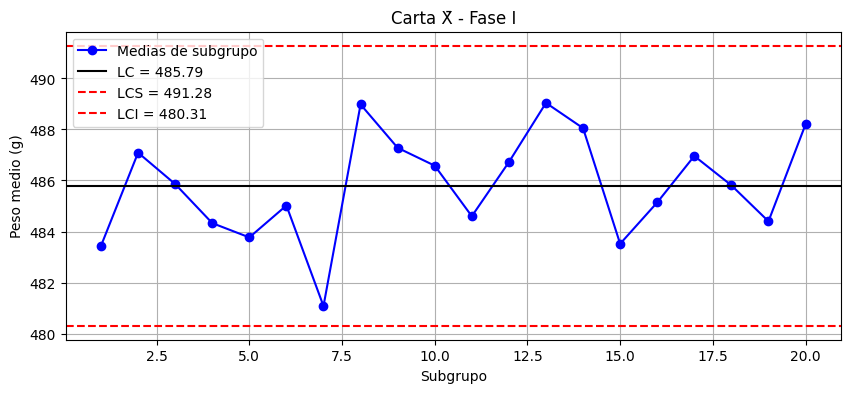

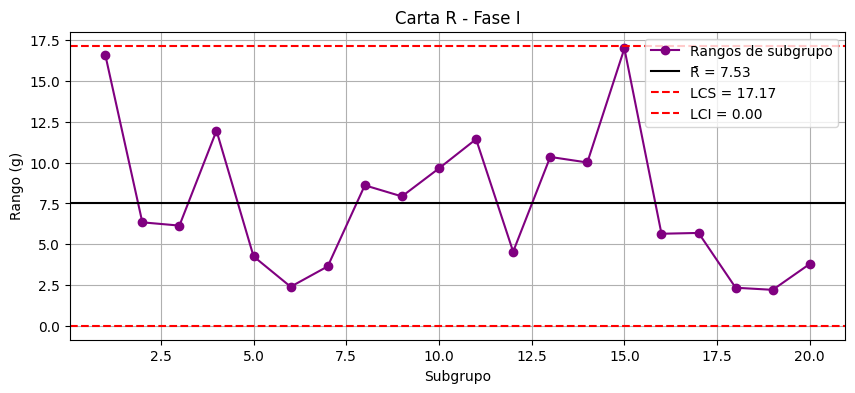

In [ ]:
# --- Carta X̄ ---
plt.figure(figsize=(10,4))

# Línea azul con las medias de cada subgrupo
plt.plot(X_prom_subgrupo.index, X_prom_subgrupo.values, marker="o", color="blue", label="Medias de subgrupo")

# Línea central (LC)
plt.axhline(X_prom_global, color="black", linestyle="-", label=f"LC = {X_prom_global:.2f}")

# Límites superior e inferior de control
plt.axhline(491.28, color="red", linestyle="--", label=f"LCS = {491.28:.2f}")
plt.axhline(480.31, color="red", linestyle="--", label=f"LCI = {480.31:.2f}")

plt.title("Carta X̄ - Fase I")
plt.xlabel("Subgrupo")
plt.ylabel("Peso medio (g)")
plt.legend()
plt.grid(True)
plt.show()


# --- Carta R ---
plt.figure(figsize=(10,4))

# Línea púrpura con los rangos de cada subgrupo
plt.plot(R_subgrupo.index, R_subgrupo.values, marker="o", color="purple", label="Rangos de subgrupo")

# Línea central (R̄)
plt.axhline(R_global, color="black", linestyle="-", label=f"R̄ = {R_global:.2f}")

# Límites superior e inferior de control
plt.axhline(17.17, color="red", linestyle="--", label=f"LCS = {17.17:.2f}")
plt.axhline(0.0, color="red", linestyle="--", label=f"LCI = {0.0:.2f}")

plt.title("Carta R - Fase I")
plt.xlabel("Subgrupo")
plt.ylabel("Rango (g)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
fase_2 = peso[peso["fase"] == "II"].copy()

fase_2.head()

X_prom_fase2 = fase_2.groupby('subgrupo')['peso_g'].mean().round(2)
X_prom_fase2

R_subgrupo_fase2 = fase_2.groupby("subgrupo")['peso_g'].agg(lambda x: x.max()-x.min()).round(2)
R_subgrupo_fase2





,peso_g
subgrupo,
21,8.72
22,6.65
23,9.46
24,1.94
25,5.93
26,2.61
27,5.85
28,6.41
29,1.91


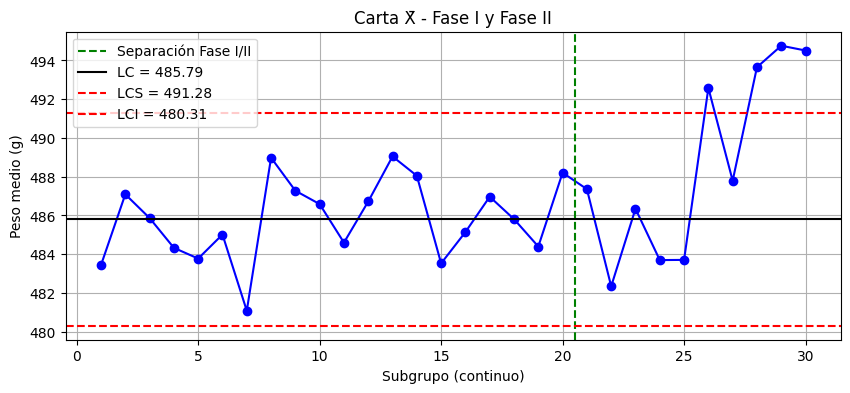

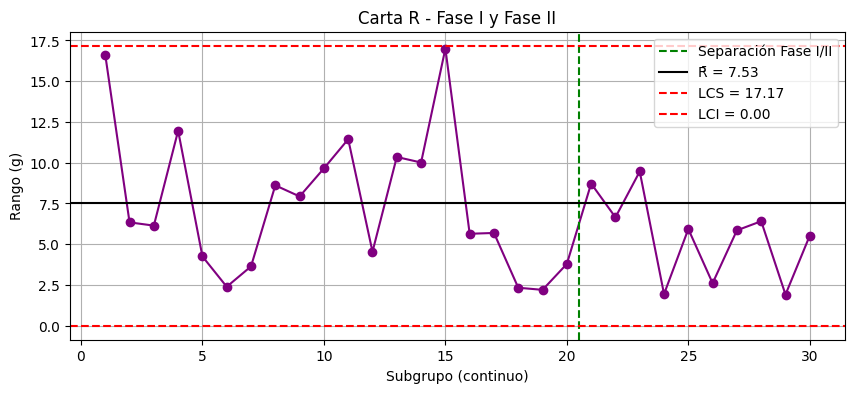

In [ ]:

# --- Medias por subgrupo y fase ---
X_prom_f1 = peso[peso["fase"]=="I"].groupby("subgrupo")["peso_g"].mean().rename("xbar")
X_prom_f2 = peso[peso["fase"]=="II"].groupby("subgrupo")["peso_g"].mean().rename("xbar")

# Concatenar y crear índice continuo
df_xbar = pd.concat([X_prom_f1, X_prom_f2], axis=0).reset_index()
df_xbar["fase"] = ["I"]*len(X_prom_f1) + ["II"]*len(X_prom_f2)

# Reindexar subgrupos para continuidad
df_xbar["subgrupo_cont"] = range(1, len(df_xbar)+1)

# --- Graficar Carta X̄ ---
plt.figure(figsize=(10,4))
plt.plot(df_xbar["subgrupo_cont"], df_xbar["xbar"], marker="o", color="blue")

# Línea verde que separa fases
sep = len(X_prom_f1)
plt.axvline(sep+0.5, color="green", linestyle="--", label="Separación Fase I/II")

# Líneas de control
plt.axhline(X_prom_global, color="black", linestyle="-", label=f"LC = {X_prom_global:.2f}")
plt.axhline(LSCX, color="red", linestyle="--", label=f"LCS = {LSCX:.2f}")
plt.axhline(LCIX, color="red", linestyle="--", label=f"LCI = {LCIX:.2f}")

plt.title("Carta X̄ - Fase I y Fase II")
plt.xlabel("Subgrupo (continuo)")
plt.ylabel("Peso medio (g)")
plt.legend()
plt.grid(True)
plt.show()


# --- Rangos por subgrupo y fase ---
R_f1 = peso[peso["fase"]=="I"].groupby("subgrupo")["peso_g"].agg(lambda x: x.max()-x.min()).rename("R")
R_f2 = peso[peso["fase"]=="II"].groupby("subgrupo")["peso_g"].agg(lambda x: x.max()-x.min()).rename("R")

df_r = pd.concat([R_f1, R_f2], axis=0).reset_index()
df_r["fase"] = ["I"]*len(R_f1) + ["II"]*len(R_f2)
df_r["subgrupo_cont"] = range(1, len(df_r)+1)

# --- Graficar Carta R ---
plt.figure(figsize=(10,4))
plt.plot(df_r["subgrupo_cont"], df_r["R"], marker="o", color="purple")

# Línea verde de separación
sep_r = len(R_f1)
plt.axvline(sep_r+0.5, color="green", linestyle="--", label="Separación Fase I/II")

# Líneas de control
plt.axhline(R_global, color="black", linestyle="-", label=f"R̄ = {R_global:.2f}")
plt.axhline(LCSR, color="red", linestyle="--", label=f"LCS = {LCSR:.2f}")
plt.axhline(LCIR, color="red", linestyle="--", label=f"LCI = {LCIR:.2f}")

plt.title("Carta R - Fase I y Fase II")
plt.xlabel("Subgrupo (continuo)")
plt.ylabel("Rango (g)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
A2,D3,D4,d2= 0.729, 0.000, 2.282, 2.059 #constantesparan=4
d = pd.read_csv('itata_peso.csv')
g =d.groupby(['fase','subgrupo'])['peso_g']
res= pd.DataFrame({'xbar': g.mean(),'R':g.max()-g.min()}).reset_index()
f1=res[res.fase=='I'] #FaseI:SOLOparacalibrar
xbb,Rb=f1.xbar.mean(),f1.R.mean()
lcs_x,lci_x=xbb+A2*Rb,xbb-A2*Rb #limitesCONGELADOS
sigma=Rb/ d2
res['fuera'] =(res.xbar >lcs_x)|(res.xbar<lci_x)
print(res.loc[res.fuera,['fase','subgrupo','xbar']])

# Crear columna booleana 'estable'
res["estable"] = res["xbar"].between(LCIX, LSCX)

# Mostrar solo las columnas relevantes
print(res[["fase","subgrupo","xbar","estable"]])


   fase  subgrupo      xbar
25   II        26  492.5800
27   II        28  493.6500
28   II        29  494.7600
29   II        30  494.5125
   fase  subgrupo      xbar  estable
0     I         1  483.4375     True
1     I         2  487.0900     True
2     I         3  485.8650     True
3     I         4  484.3275     True
4     I         5  483.7725     True
5     I         6  485.0150     True
6     I         7  481.0800     True
7     I         8  488.9800     True
8     I         9  487.2750     True
9     I        10  486.5850     True
10    I        11  484.5975     True
11    I        12  486.7200     True
12    I        13  489.0450     True
13    I        14  488.0475     True
14    I        15  483.5250     True
15    I        16  485.1425     True
16    I        17  486.9650     True
17    I        18  485.8100     True
18    I        19  484.3950     True
19    I        20  488.2050     True
20   II        21  487.3575     True
21   II        22  482.3400     True
22   II  

In [ ]:
desv_est_sg= (R_global/d2)

print(desv_est_sg)

3.6551724137931028


In [ ]:
print(' No se observan puntos fuera de control en ninguna de las dos cartas.' , '\n' ,'Los resultados son compatibles con un proceso estable según la regla de tres sigmas,' , '\n' , 'aunque faltaría revisar otras reglas de detección de patrones antes de confirmarlo definitivamente.   ' , '\n\n')

print('''Primero, carta (R): los subgrupos 21 al 30 permanecen dentro de los límites establecidos.
No se detectan señales de aumento anormal de la dispersión mediante la regla de tres sigmas.'''  , '\n' ,'''
Segundo, carta X̄: los subgrupos 26, 28, 29 y 30 aproximadamente superan el límite superior de 491,28 g.
Esto indica un desplazamiento ascendente de la media del peso escurrido.''', '\n' ,'''
Por tanto, el proceso presenta señales de inestabilidad en su media durante la Fase II,
aunque su dispersión dentro de los subgrupos no presenta señales equivalentes.''')



 No se observan puntos fuera de control en ninguna de las dos cartas. 
 Los resultados son compatibles con un proceso estable según la regla de tres sigmas, 
 aunque faltaría revisar otras reglas de detección de patrones antes de confirmarlo definitivamente.    


Primero, carta (R): los subgrupos 21 al 30 permanecen dentro de los límites establecidos.
No se detectan señales de aumento anormal de la dispersión mediante la regla de tres sigmas. 
 
Segundo, carta X̄: los subgrupos 26, 28, 29 y 30 aproximadamente superan el límite superior de 491,28 g.
Esto indica un desplazamiento ascendente de la media del peso escurrido. 
 
Por tanto, el proceso presenta señales de inestabilidad en su media durante la Fase II,
aunque su dispersión dentro de los subgrupos no presenta señales equivalentes.


#EJERCICIO 3;
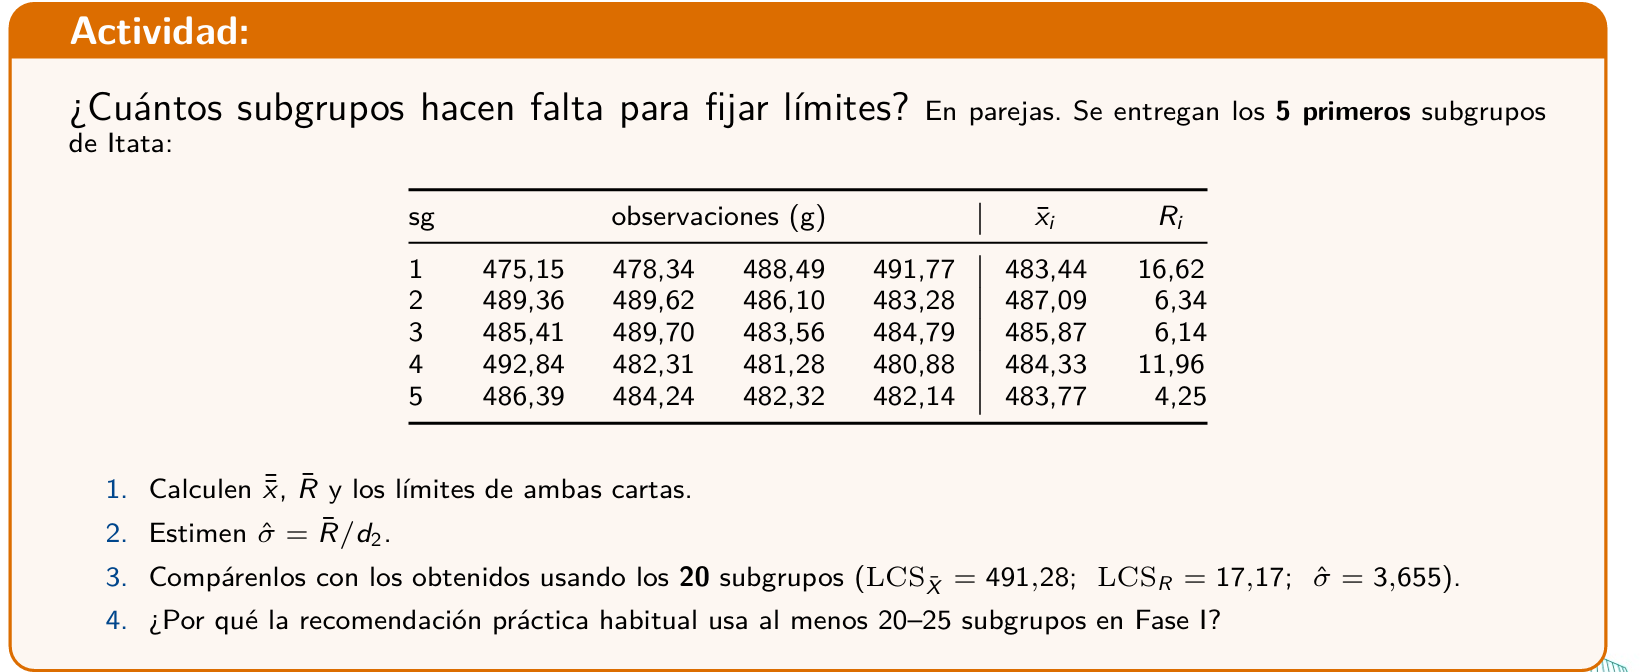

In [ ]:
data = {
    "sg": [1, 2, 3, 4, 5],
    "observaciones": [
        [475.15, 478.34, 488.49, 491.77],
        [489.36, 489.62, 486.10, 483.28],
        [485.41, 489.70, 483.56, 484.79],
        [492.84, 482.31, 481.28, 480.88],
        [486.39, 484.24, 482.32, 482.14]
    ],
    "x̄ᵢ": [483.44, 487.09, 485.87, 484.33, 483.77],
    "Rᵢ": [16.62, 6.34, 6.14, 11.96, 4.25]
}


data = pd.DataFrame(data).set_index('sg')


data.head()

,observaciones,x̄ᵢ,Rᵢ
sg,,,
1,"[475.15, 478.34, 488.49, 491.77]",483.44,16.62
2,"[489.36, 489.62, 486.1, 483.28]",487.09,6.34
3,"[485.41, 489.7, 483.56, 484.79]",485.87,6.14
4,"[492.84, 482.31, 481.28, 480.88]",484.33,11.96
5,"[486.39, 484.24, 482.32, 482.14]",483.77,4.25


In [ ]:

Xprom = data["x̄ᵢ"].mean().round(2)
Rprom = data["Rᵢ"].mean().round(3)




#PARTE 1
A2 = 0.729
D3 = 0
D4 = 2.282
d2 = 2.059

#Se puede estimar la desvest?
lcs_X = Xprom + A2*Rprom
lci_X = Xprom - A2*Rprom
lcs_r = D4*Rprom
lci_r = D3*Rprom

print('Limite de Control Superior para el peso escurrido en gramos: ', str(lcs_X))
print('Limite de Control Inferior para el peso escurrido en gramos: ', str(lci_X))
print('Límite de Control Superior para el rango es: ', str(  lcs_r))
print('Límite de Control Inferior para el rango es: ', str(  lci_r))


# Función para verificar si alguna observación está fuera de los límites
def fuera_de_control(obs_list, lci, lcs):
    return any((x < lci) or (x > lcs) for x in obs_list)

# Columna booleana: True si el subgrupo tiene alguna observación fuera de control
data["x̄ᵢ_fuera_control"] = data["observaciones"].apply(lambda x: fuera_de_control(x, lci_X, lcs_X))
data["Rᵢ_fuera_control"] = data["Rᵢ"].apply(lambda r: (r < lci_r) or (r > lcs_r))
print(data[["observaciones","x̄ᵢ","Rᵢ","x̄ᵢ_fuera_control"]])
print(data[["Rᵢ","Rᵢ_fuera_control"]])


#PARTE 2
desv_est = Rprom/d2
print(desv_est, ' esta desviación no es válida')



#PARTE 3
print('\n\n\n\n',     'se puede ver que al comparar los resultados entre los subgrupos,','\n','la carta X tiene un intervalo más amplio cuando son menos grupos, en otras palabras el intervalo de control es más amplio, esto implica ','\n',' que con 20 subgrupos hay una estimación más precisa de los limites de control')
print('\n\n\n\n', 'Se puede ver también que los límites de la carta R permiten menos variabilidad estimada')
print('\n\n\n\n', 'la desviación estándar cae en un 17% al pasar de 3.655 a:', desv_est)

#PARTE 4
print('está establecido como una práctica estándar porque permite estimar los límtes de control con una precisión razonable','\n', 'esto se debe a que como hay más datos la muestra resulta menos sensible a la presencia de valores atípicos.', '\n', 'Además existe una mayor cantidad de periodos por lo que es más facil observar cambios o tendencias' , '\n', 'puede permitir cubrir más horarios dentro del proceso, es decir, incluye una visión más amplia.')




Limite de Control Superior para el peso escurrido en gramos:  491.506198
Limite de Control Inferior para el peso escurrido en gramos:  478.29380199999997
Límite de Control Superior para el rango es:  20.679484
Límite de Control Inferior para el rango es:  0.0
                       observaciones     x̄ᵢ     Rᵢ  x̄ᵢ_fuera_control
sg                                                                    
1   [475.15, 478.34, 488.49, 491.77]  483.44  16.62               True
2    [489.36, 489.62, 486.1, 483.28]  487.09   6.34              False
3    [485.41, 489.7, 483.56, 484.79]  485.87   6.14              False
4   [492.84, 482.31, 481.28, 480.88]  484.33  11.96               True
5   [486.39, 484.24, 482.32, 482.14]  483.77   4.25              False
       Rᵢ  Rᵢ_fuera_control
sg                         
1   16.62             False
2    6.34             False
3    6.14             False
4   11.96             False
5    4.25             False
4.40116561437591  esta desviación no es válida


#EJERCICIO 4 CAPACIDAD


In [ ]:

#Limites de especificación
LSE, LIE = 495, 465

#Cálculo de la capacidad potencial
Capacidad_potencial = ((LSE-LIE)/(desv_est_sg*6)).round(3)
print('Capacidad potencial: ', Capacidad_potencial)
print('\n','Está por sobre la referencia habitual.')

#Cálculo de la capacidad real

mhu = X_prom_global.round(2)
print('\n','Media del proceso: ' ,mhu) # O media del proceso.

Holgura_LIMITESUPERIOR = (LSE-mhu)/(3*desv_est_sg).round(3)
print('\n', 'Holgura respecto al limite superior: ' ,Holgura_LIMITESUPERIOR)

Holgura_LIMITEINFERIOR = (mhu-LIE)/(3*desv_est_sg).round(3)
print('\n','Holgura respecto al limite inferior: ' ,Holgura_LIMITEINFERIOR)

Capacidad_real= min(Holgura_LIMITEINFERIOR, Holgura_LIMITESUPERIOR).round(3)
print('\n', 'Capacidad real: ' ,Capacidad_real)


m = (LSE+LIE)/2
print('\n','Punto Medio de Especificación: ' ,m)
a= ((LSE-LIE)/2)
k = (abs(mhu-m)/a).round(3)
print('\n','Margen gastado en estar corrido: ',k)


#Cociente diagnóstico
Cociente_Diagnóstico = (Capacidad_potencial/Capacidad_real).round(2)
print('\n','Cociente de Diagnóstico: ',Cociente_Diagnóstico)

if Cociente_Diagnóstico ==1:
  print('\n','El cociente de diagnóstico es: ',Cociente_Diagnóstico,'. El proceso está centrado.')
else:
  print('\n','El cociente de diagnóstico es: ',Cociente_Diagnóstico,'. El proceso no está centrado.')

print('\n\n\n','En este caso el proceso tiene capacidad potencial: ' + str(Capacidad_potencial.round(2)) + ' .', '\n', 'Mientras que la capacidad real es: ' + str(Capacidad_real) + ' osea, es incapaz y el problema central es el centrado: el proceso se está sobrellenando.' )

Capacidad potencial:  1.368

 Está por sobre la referencia habitual.

 Media del proceso:  485.79

 Holgura respecto al limite superior:  0.8399452804377546

 Holgura respecto al limite inferior:  1.896032831737348

 Capacidad real:  0.84

 Punto Medio de Especificación:  480.0

 Margen gastado en estar corrido:  0.386

 Cociente de Diagnóstico:  1.63

 El cociente de diagnóstico es:  1.63 . El proceso no está centrado.



 En este caso el proceso tiene capacidad potencial: 1.37 . 
 Mientras que la capacidad real es: 0.84 osea, es incapaz y el problema central es el centrado: el proceso se está sobrellenando.


#Desempeño: Pp, Ppk.

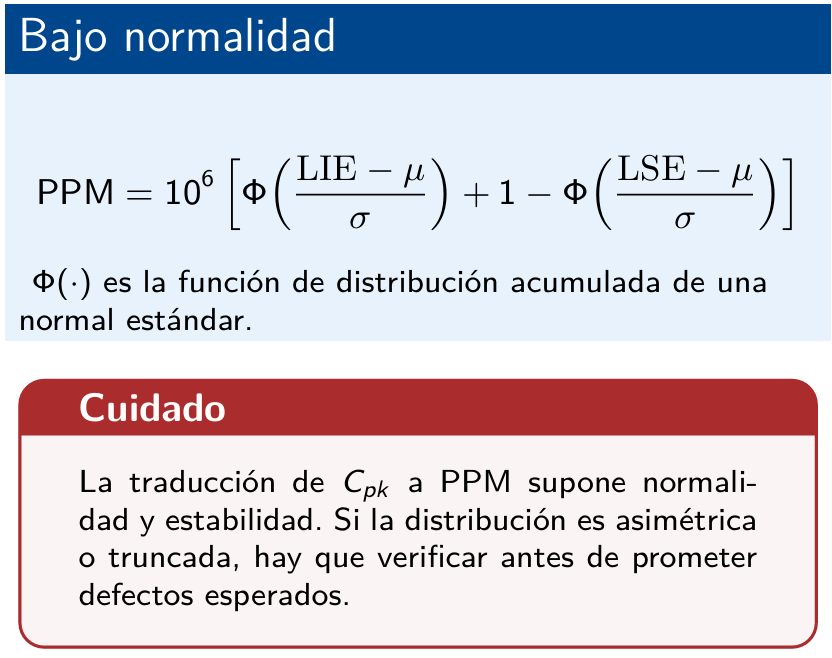




#Ejercicio 5, ¿Recentrar o reducir la variabilidad?

##Capacidad  y Partes por millon.

##Se debe corroborar normalidad y estabilidad antes.

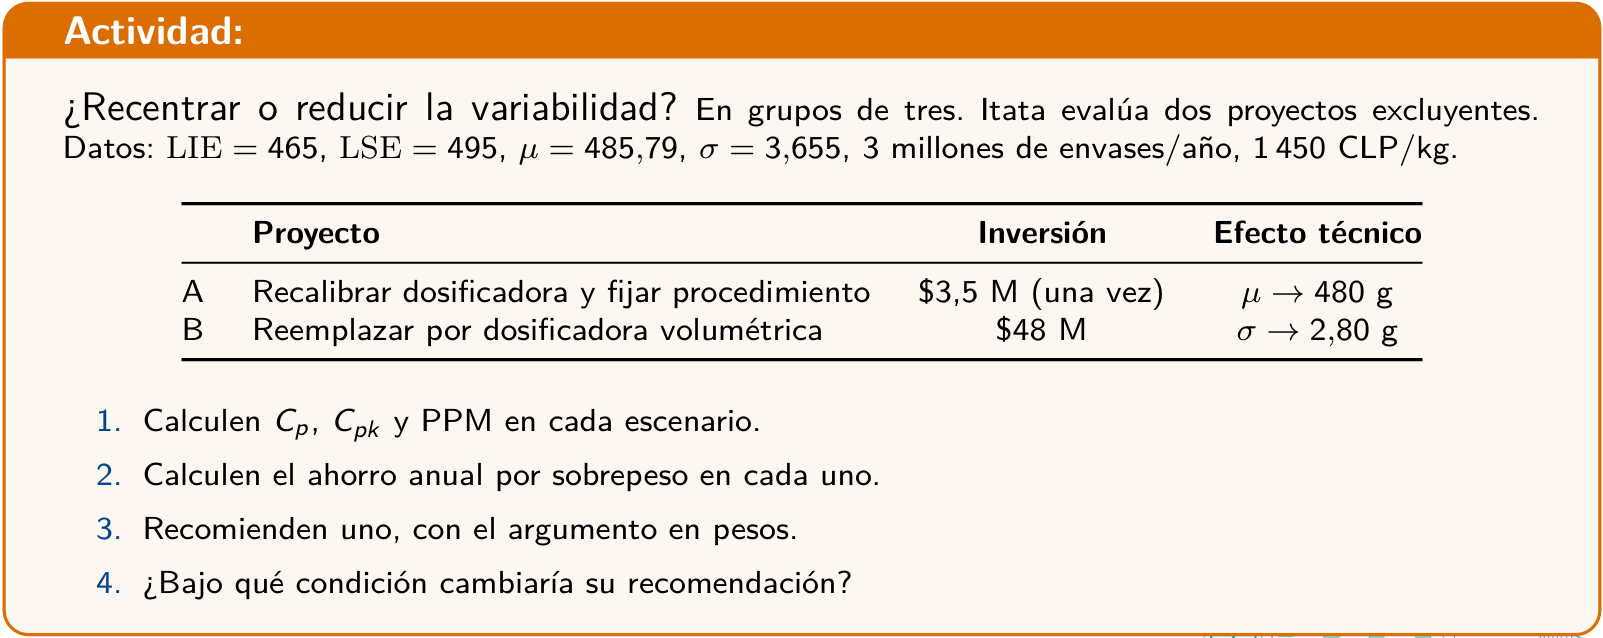

In [ ]:
LIE = 465
LSE = 495
mhu = 485.794
desv_est_sg = desv_est_sg

n_de_envases_x_anio = 3*(10**6)
costo_x_kg = 1450

##ETAPA 1
Cp  =  ((LSE-LIE)/(6*desv_est_sg))
print('Capacidad potencial: ',round(Cp, 3))

Cpu = (LSE-mhu)/(3*desv_est_sg)
Cpi = (mhu-LIE)/(3*desv_est_sg)
print('Holgura Superior Capacidad: ' , round(Cpu, 3))
print('Holgura Inferior Capacidad: ' , round(Cpi, 3))

Cpk = min(Cpu, Cpi)
print('Capacidad Real: ', round(Cpk, 3))



# Cálculo de PPM
z_inf = (LIE - mhu) / desv_est_sg
z_sup = (LSE - mhu) / desv_est_sg

PPM = (10**6 *(1 - stats.norm.cdf((LSE-mhu)/desv_est_sg) +   stats.norm.cdf((LIE-mhu)/desv_est_sg))).round(0)

print("PPM =", round(PPM, 2))


##ETAPA 2

Capacidad potencial:  1.368
Holgura Superior Capacidad:  0.84
Holgura Inferior Capacidad:  1.896
Capacidad Real:  0.84
PPM = 5891.0
17370.0
25186500.0

El proyecto A ahorra un total de:  25186500 [CLP/año ] que corresponde al costo anual por sobrepeso.
El proyecto B cambia la desviación estándar de:  3.655 a:  2.8 sin embargo, no afecta a la media, el sobrepeso se mantiene y el costo también.


In [ ]:
#RECALCULANDO con los resultados del proyecto A.

CpA = ((LSE-LIE)/(6*desv_est_sg))


CpuA = (LSE-480)/(3*desv_est_sg)
CpiA = (480-LIE)/(3*desv_est_sg)
print('Holgura Superior Capacidad: ' , round(CpuA, 3))
print('Holgura Inferior Capacidad: ' , round(CpiA, 3))

CpkA = min(CpuA, CpiA)
print('Capacidad Real: ', round(CpkA, 3))

PPMA = (10**6 *(1 - stats.norm.cdf((LSE-480)/desv_est_sg) +   stats.norm.cdf((LIE-480)/desv_est_sg))).round(0)
print(PPM)

CAxSP_A = ((480-480)*n_de_envases_x_anio) * costo_x_kg/1000
print('Costo anual: ', round(CAxSP_A, 2))



print('El proyecto elimina los costos anuales por sobrepeso.')

Holgura Superior Capacidad:  1.368
Holgura Inferior Capacidad:  1.368
Capacidad Real:  1.368
505.0
Costo anual:  0.0


In [ ]:
##RECALCULANDO con los resultados del proyecto B.
CpB = ((LSE-LIE)/(6*2.8))
print('Capacidad potencial: ',round(CpB, 3))

CpuB = (LSE-mhu)/(3*2.8)
CpiB = (mhu-LIE)/(3*2.8)
print('Holgura Superior Capacidad: ' , round(CpuB, 3))
print('Holgura Inferior Capacidad: ' , round(CpiB, 3))

CpkB = min(CpuB, CpiB)
print('Capacidad Real: ', round(CpkB, 3))


PPMB = (10**6 *(1 - stats.norm.cdf((LSE-mhu)/2.8) +   stats.norm.cdf((LIE-mhu)/2.8))).round(0)
print("PPM =", round(PPM, 2))


CAxSP_B = ((round(mhu,2)-480)*n_de_envases_x_anio) * costo_x_kg/1000
print('Costo anual: ', round(CAxSP_B, 2))


print('El proyecto NO elimina los costos anuales por sobrepeso.')


Capacidad potencial:  1.786
Holgura Superior Capacidad:  1.096
Holgura Inferior Capacidad:  2.475
Capacidad Real:  1.096
PPM = 505.0
Costo anual:  25186500.0
El proyecto NO elimina los costos anuales por sobrepeso.


In [ ]:
##RECALCULANDO CON AMBOS
CpAB = ((LSE-LIE)/(6*2.8))
print('Capacidad potencial: ',round(CpAB, 3))

CpuAB = (LSE-480)/(3*2.8)
CpiAB = (480-LIE)/(3*2.8)
print('Holgura Superior Capacidad: ' , round(CpuAB, 3))
print('Holgura Inferior Capacidad: ' , round(CpiAB, 3))

CpkAB= min(CpuAB, CpiAB)
print('Capacidad Real: ', round(CpkAB, 3))

PPMAB = (10**6 *(1 - stats.norm.cdf((LSE-480)/2.8) +   stats.norm.cdf((LIE-480)/2.8))).round(0)
print("PPM =", round(PPM, 2))

CAxSP_AB = ((480-480)*n_de_envases_x_anio) * costo_x_kg/1000
print('Costo anual: ', round(CAxSP_AB, 2))


print('El proyecto elimina los costos anuales por sobrepeso.')

Capacidad potencial:  1.786
Holgura Superior Capacidad:  1.786
Holgura Inferior Capacidad:  1.786
Capacidad Real:  1.786
PPM = 505.0
Costo anual:  0.0


In [ ]:
##ETAPA 3,

print('la recomendación es aplicar solamente el proyecto A, es el único que tiene un efecto real en los costos anuales pr sobrepeso. ')

print(48/3.5)

print('además es practicamente 14 veces más caro.')


PaybackA = (3.5*10**6)/CAxSP_B

print('La inversión se recupera en: ',round(PaybackA*12,1), 'meses.')

print('Además, CpkA: ', CpkA, ' es mejor que el Cpk anterior: ',Cpk,'Y se encuentra por sobre el umbral habitual de 1.33, sin acercarse a ser un proceso crítico o exigente.')

la recomendación es aplicar solamente el proyecto A, es el único que tiene un efecto real en los costos anuales pr sobrepeso. 
13.714285714285714
además es practicamente 14 veces más caro.
La inversión se recupera en:  1.7 meses.
Además, CpkA:  1.367924528301887  es mejor que el Cpk anterior:  1.367924528301887 Y se encuentra por sobre el umbral habitual de 1.33, sin acercarse a ser un proceso crítico o exigente.


In [ ]:
##Etapa 4

priint('solo cambiaría de opinión en el caso que la inversión en el proyecto B generara los suficientes retornos como para justificar su inversión, reducir los de reproceso o generar otros ahorros operacionales.')

#EJERCICIO 5  CARTA p, inspección de lotes ITATA

In [ ]:
atributos = pd.read_csv('itata_atributos.csv')
atributos.info()
print(atributos)


atributos['p_i'] = atributos['n_defectuosas'] / atributos['n_inspeccionadas']
atributos.head()

p_global = atributos['n_defectuosas'].sum() / atributos['n_inspeccionadas'].sum()
print('\n\n\n','='*150,'\n\n\np_global es: ',p_global, 'en otras palabras es la proporción acumulada de las unidades defectuosas.')


LCentralp= p_global

##Límites de control.
LCI_i, LCS_i = p_global - 3*( p_global*(1-p_global)/(atributos['n_inspeccionadas'])  )**0.5 , p_global + 3*( p_global*(1-p_global)/(atributos['n_inspeccionadas'])  )**0.5
atributos['LCI_i'] = LCI_i
atributos['LCS_i'] = LCS_i
atributos.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   lote              24 non-null     int64 
 1   n_inspeccionadas  24 non-null     int64 
 2   n_defectuosas     24 non-null     int64 
 3   causa_principal   24 non-null     object
dtypes: int64(3), object(1)
memory usage: 900.0+ bytes
    lote  n_inspeccionadas  n_defectuosas      causa_principal
0      1               260             13  Peso fuera de rango
1      2               296             18  Peso fuera de rango
2      3               319             12  Peso fuera de rango
3      4               318             14             Rotulado
4      5               254             12  Peso fuera de rango
5      6               351             12     Sello defectuoso
6      7               367             10     Sello defectuoso
7      8               278              5  Peso fuera de rango


,lote,n_inspeccionadas,n_defectuosas,causa_principal,p_i,LCI_i,LCS_i
0,1,260,13,Peso fuera de rango,0.050000,0.003852,0.077247
1,2,296,18,Peso fuera de rango,0.060811,0.006156,0.074943
2,3,319,12,Peso fuera de rango,0.037618,0.007419,0.073680
3,4,318,14,Rotulado,0.044025,0.007367,0.073732
4,5,254,12,Peso fuera de rango,0.047244,0.003421,0.077678


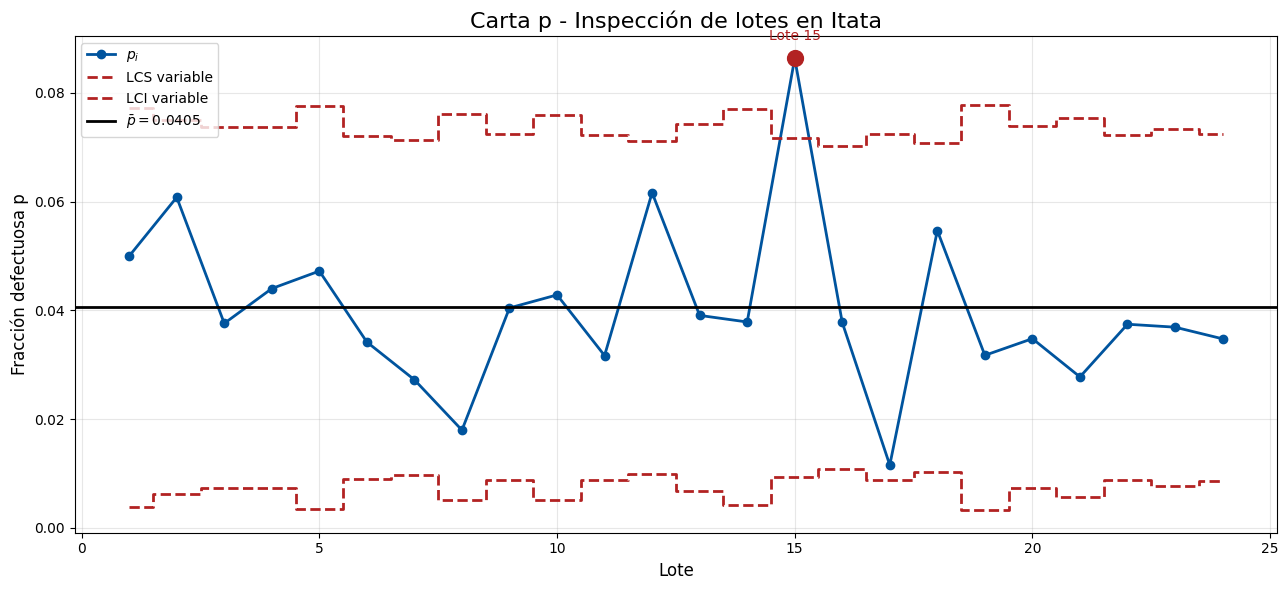

Proporción global: 0.0405
Lotes analizados: 24
Lotes fuera de control: 1


,lote,p_i,LCI_i,LCS_i,causa_principal
14,15,0.086351,0.009319,0.07178,Sello defectuoso


In [ ]:
# Crear gráfico
fig, ax = plt.subplots(figsize=(13, 6))
df= atributos
fuera = (df['p_i'] > df['LCS_i']) | (df['p_i'] < df['LCI_i'])



# Proporción defectuosa de cada lote
ax.plot(df['lote'], df['p_i'],
        '-o', color='#00549E', linewidth=2,
        markersize=6, label=r'$p_i$')

# Límites de control variables
ax.step(df['lote'], df['LCS_i'],
        where='mid', color='firebrick',
        linestyle='--', linewidth=2,
        label='LCS variable')

ax.step(df['lote'], df['LCI_i'],
        where='mid', color='firebrick',
        linestyle='--', linewidth=2,
        label='LCI variable')

# Línea central
ax.axhline(p_global, color='black', linewidth=2,
           label=fr'$\bar{{p}} = {p_global:.4f}$')

# Destacar lotes fuera de control
ax.scatter(df.loc[fuera, 'lote'],
           df.loc[fuera, 'p_i'],
           color='firebrick', s=130, zorder=5)

# Etiquetar los lotes fuera de control
for _, fila in df[fuera].iterrows():
    ax.annotate(
        f"Lote {int(fila['lote'])}",
        (fila['lote'], fila['p_i']),
        xytext=(0, 13),
        textcoords='offset points',
        ha='center',
        color='firebrick'
    )

# Formato
ax.set_title('Carta p - Inspección de lotes en Itata', fontsize=16)
ax.set_xlabel('Lote', fontsize=12)
ax.set_ylabel('Fracción defectuosa p', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

# Resumen
print(f"Proporción global: {p_global:.4f}")
print(f"Lotes analizados: {len(df)}")
print(f"Lotes fuera de control: {fuera.sum()}")

display(df.loc[fuera, ['lote', 'p_i', 'LCI_i', 'LCS_i', 'causa_principal']])

In [ ]:
##Buscamos la familiia de defecto.
#SE APLICA PARETO

atributos.head()
print(atributos['causa_principal'].unique())


df_pareto= atributos.groupby('causa_principal').sum().sort_values('n_inspeccionadas', ascending=False)
df_pareto = df_pareto.drop(columns=['lote','p_i', 'LCI_i', 'LCS_i','n_inspeccionadas'])
df_pareto['Acumulado'] = df_pareto['n_defectuosas'].cumsum().div(df_pareto['n_defectuosas'].sum()).round(3)


df_pareto.head()



['Peso fuera de rango' 'Rotulado' 'Sello defectuoso' 'Abolladura']


,n_defectuosas,Acumulado,%
causa_principal,,,
Sello defectuoso,157,0.502,0.502
Peso fuera de rango,96,0.808,0.307
Rotulado,56,0.987,0.179
Abolladura,4,1.000,0.013


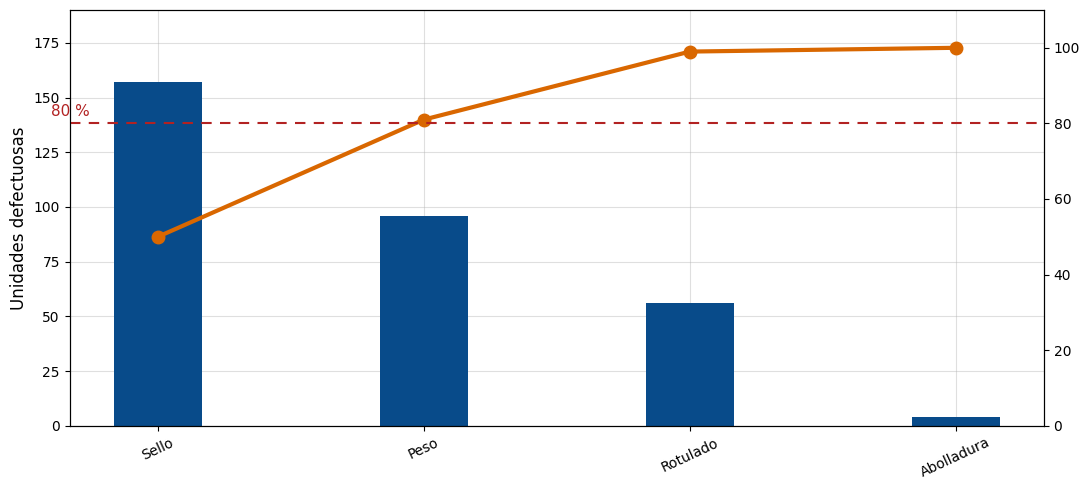

In [ ]:
# Posiciones en el eje X
x = np.arange(len(df_pareto))

# Crear figura
fig, ax1 = plt.subplots(figsize=(11, 5))

# Barras: unidades defectuosas
ax1.bar(x,df_pareto['n_defectuosas'],color='#084B8A',width=0.33)

ax1.set_ylabel('Unidades defectuosas', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(['Sello', 'Peso', 'Rotulado', 'Abolladura'],rotation=25)
ax1.set_ylim(0, 190)
ax1.grid(True, alpha=0.4)
ax1.set_axisbelow(True)

# Segundo eje: porcentaje acumulado
ax2 = ax1.twinx()

ax2.plot(x,df_pareto['Acumulado'] * 100,color='#D96700',marker='o',linewidth=3,markersize=9)

ax2.set_ylim(0, 110)
ax2.set_yticks(np.arange(0, 101, 20))

# Línea de referencia del 80 %
ax2.axhline(y=80,color='firebrick',linestyle='--',linewidth=1.5,dashes=(5, 4))

ax2.text(-0.4, 82,'80 %',color='firebrick',fontsize=11)

plt.tight_layout()
plt.show()

#EJERCICIO 6 Muestreo de Aceptación.

In [ ]:
oc = pd.read_csv('oc_plan.csv')
oc.info()
atributos.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   p                   41 non-null     float64
 1   Pa_binomial         41 non-null     float64
 2   Pa_hipergeometrica  41 non-null     float64
dtypes: float64(3)
memory usage: 1.1 KB


,lote,n_inspeccionadas,n_defectuosas,causa_principal,p_i,LCI_i,LCS_i
0,1,260,13,Peso fuera de rango,0.050000,0.003852,0.077247
1,2,296,18,Peso fuera de rango,0.060811,0.006156,0.074943
2,3,319,12,Peso fuera de rango,0.037618,0.007419,0.073680
3,4,318,14,Rotulado,0.044025,0.007367,0.073732
4,5,254,12,Peso fuera de rango,0.047244,0.003421,0.077678


In [ ]:
print(oc)


         p  Pa_binomial  Pa_hipergeometrica
0   0.0000       1.0000              1.0000
1   0.0025       0.9989              0.9994
2   0.0050       0.9923              0.9940
3   0.0075       0.9774              0.9802
4   0.0100       0.9534              0.9570
5   0.0125       0.9209              0.9247
6   0.0150       0.8808              0.8845
7   0.0175       0.8348              0.8379
8   0.0200       0.7844              0.7867
9   0.0225       0.7312              0.7325
10  0.0250       0.6767              0.6769
11  0.0275       0.6220              0.6210
12  0.0300       0.5681              0.5661
13  0.0325       0.5159              0.5130
14  0.0350       0.4661              0.4623
15  0.0375       0.4189              0.4144
16  0.0400       0.3748              0.3697
17  0.0425       0.3339              0.3284
18  0.0450       0.2962              0.2905
19  0.0475       0.2618              0.2560
20  0.0500       0.2306              0.2247
21  0.0525       0.2024         